# 04 — Factor models (`EXP-H03`)

## 1. Objective
Test whether lagged cross-asset factor residual state improves BTCUSDT return-density forecasts beyond own-price history.

## 2. Hypothesis
Lagged single-market-factor or PCA residuals improve 5-, 15-, and 60-minute predictive density.

## 3. Null
Neither factor residual model improves out-of-sample log score over the nested own-price model at every declared horizon.

## 4. Information set
One-minute closes for the frozen Binance major panel. Own-price and factor features are delayed by one minute. Normalisation, betas, PCA loadings, and density parameters are fit on training data only.

## 5. Dataset
`binance-majors-1m`: BTCUSDT target plus ETHUSDT, BNBUSDT, XRPUSDT, ADAUSDT, and SOLUSDT. The aggregate manifest binds each member object version and complete-case alignment interval.

## 6. Data quality
Each member receives the standard minute-bar audit. Cross-asset timestamps are inner-aligned without forward filling; all excluded timestamps and post-freeze collector rows are counted.

## 7. Labels
Forward BTCUSDT log returns at 5, 15, and 60 minutes. A label belongs to a split only when its outcome is known inside that split.

## 8. Baseline
A Gaussian or Student-t conditional-location density using lagged BTCUSDT one-minute return and 60-minute realised volatility. The residual family is selected by H1.

## 9. Model family
Add either the lagged BTC residual from an equal-weight peer market factor or the lagged BTC residual from two-component PCA. PCA versus the single-factor model addresses strategy.md §21.3.

## 10. Splits
24-month train, 6-month validation, 6-month step, and final 12-month untouched test.

## 11. Configuration
The source of truth is `research.protocol.H3_CONFIG`. The development path cannot retain H3; sealed confirmation requires a resolved H1 record and committed code.

In [1]:
import os
import sys
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

root = Path.cwd().resolve()
while root != root.parent and not (root / "research" / "__init__.py").exists():
    root = root.parent
if not (root / "research" / "__init__.py").exists():
    raise RuntimeError("open this notebook from the trading repository")
os.chdir(root)
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
os.environ.setdefault("AWS_PROFILE", "trading")
os.environ.setdefault("AWS_DEFAULT_REGION", "ap-southeast-2")
os.environ.setdefault("DATA_STORE", "s3")
os.environ.setdefault("S3_BUCKET", "trading-data-centheos")
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:.6g}".format)

from research.registry import config_digest, load_record
from research.report import (
    calibration_summary,
    confirmation_blockers,
    model_colors,
    plain_english_result,
    plot_advantage_by_origin,
    plot_density_panels,
    plot_pit_qq,
    plot_score_levels,
    plot_shortfall,
    plot_var_hit_rates,
    quality_table,
    record_development_decision,
    score_reading,
)

## 5–6. Dataset and data quality

The frozen manifest is reloaded and verified. Every audit exclusion is counted in the table.

In [2]:
from research.evaluate import align_to_frozen_panel, freeze_panel_dataset
from research.load import load_research_panel
from research.manifest import load_panel_manifest, save_panel_manifest
from research.protocol import H3_CONFIG

symbols = tuple(H3_CONFIG["symbols"])
bars_by_symbol, objects_by_symbol = load_research_panel(
    venue=H3_CONFIG["venue"],
    symbols=symbols,
    timeframe=H3_CONFIG["timeframe"],
    bucket=H3_CONFIG["bucket"],
    profile=H3_CONFIG["profile"],
    region=H3_CONFIG["region"],
)
panel_manifest_path = root / "research" / "registry" / "datasets" / "binance-majors-1m.json"
if panel_manifest_path.exists():
    panel_manifest = load_panel_manifest(panel_manifest_path)
    panel_closes, quality_reports, collector_rows_after_freeze = align_to_frozen_panel(
        bars_by_symbol, panel_manifest, objects_by_symbol
    )
else:
    panel_closes, panel_manifest, quality_reports = freeze_panel_dataset(
        bars_by_symbol,
        objects_by_symbol,
        dataset_id=H3_CONFIG["panel_dataset_id"],
        symbols=symbols,
        venue=H3_CONFIG["venue"],
        timeframe=H3_CONFIG["timeframe"],
        bucket=H3_CONFIG["bucket"],
        profile=H3_CONFIG["profile"],
    )
    save_panel_manifest(panel_manifest_path, panel_manifest)
    collector_rows_after_freeze = {symbol: 0 for symbol in symbols}
print(f"panel {panel_manifest.dataset_id} digest {panel_manifest.digest}")
print(f"aligned rows {len(panel_closes)}; timestamps dropped by complete-case alignment {panel_manifest.alignment_exclusions}")
quality = quality_table(quality_reports)
quality["collector_rows_after_freeze"] = pd.Series(collector_rows_after_freeze)
display(quality)

Excluded 10737 collector rows after frozen end 2026-10-18T22:35:00+00:00; ohlcv/binance/BTCUSDT/1m/2026.parquet etag d9a8c2e0a0d211a9f50c9af0b06f7da8 -> 9970509376d39c14e5d0558776dd454b, size 5537421 -> 5816494
Excluded 10737 collector rows after frozen end 2026-10-18T22:35:00+00:00; ohlcv/binance/ETHUSDT/1m/2026.parquet etag b7a8dff54796e9f358703d3305774822 -> 930a820c361e3ff838fd512941c22926, size 5106061 -> 5359777
Excluded 10737 collector rows after frozen end 2026-10-18T22:35:00+00:00; ohlcv/binance/BNBUSDT/1m/2026.parquet etag a6a709842cdfbafcd5f0ec5cdad1e837 -> 0219bb27c729068ad4da4b19c659e21c, size 3730131 -> 3926342
Excluded 10737 collector rows after frozen end 2026-10-18T22:35:00+00:00; ohlcv/binance/XRPUSDT/1m/2026.parquet etag 42b027e085656e582aafa233e74113f2 -> a5b29fb197e591af9d7da14c7dca03ec, size 8616089 -> 8814339
Excluded 10737 collector rows after frozen end 2026-10-18T22:35:00+00:00; ohlcv/binance/ADAUSDT/1m/2026.parquet etag bc0089aedb6382a6616acd63bec4444d -> 662

panel binance-majors-1m digest 521d37ac1ceb1825b8734b8128760b88acfc6d41010c0d6f1ac4cf3b469e0696
aligned rows 3204936; timestamps dropped by complete-case alignment 370500


,rows_in,rows_kept,duplicate_timestamps,off_grid_timestamps,nonpositive_prices,inconsistent_ohlc,missing_minutes,largest_gap_minutes,collector_rows_after_freeze
series,,,,,,,,,
BTCUSDT,3575436,3575436,0,0,0,0,0,1,10737
ETHUSDT,3575436,3575436,0,0,0,0,0,1,10737
BNBUSDT,3517355,3517355,0,0,0,0,0,1,10737
XRPUSDT,3567735,3567735,0,0,0,0,0,1,10737
ADAUSDT,3531755,3531755,0,0,0,0,0,1,10737
SOLUSDT,3204936,3204936,0,0,0,0,0,1,10737


## 12–17. Evaluation

The evaluation compares own-price history with own-price plus a lagged single crypto-factor residual, and with own-price plus a lagged crypto PCA residual, at every rolling origin. The null is rejected only when a factor model has a positive mean and median log-score advantage at every horizon. PCA is preferred over the single factor only if it also beats it.

- **12. Statistical evaluation.** Mean log score per walk-forward origin, PIT, and VaR coverage on the fixed model-by-horizon family.
- **13. Economic evaluation.** None. This hypothesis is predictive only.
- **14. Calibration.** PIT QQ and Bonferroni-adjusted VaR coverage, below.
- **15. Ablation.** The nested sequence is listed in §9.
- **16. Robustness.** Every rolling origin and every registered horizon must agree. A change of configuration is a new experiment.
- **17. Failure analysis.** Failed windows, exclusions, and gaps are counted and printed. A failed window is never scored as zero.

In [3]:
from research.evaluate import evaluate_h3, h3_development_decision, h3_development_fits, h3_log_score_comparison, h3_var_coverage_family

CONFIG = H3_CONFIG
EXPERIMENT_ID = "EXP-H03"
RECORD_PATH = root / "research" / "registry" / "EXP-H03.json"
DATASET_ID, DATASET_DIGEST = panel_manifest.dataset_id, panel_manifest.digest
h1_record = load_record(root / "research" / "registry" / "EXP-H01.json")
print("configuration digest:", config_digest(CONFIG))
print(f"H1 status={h1_record.status} result={h1_record.result} decision={h1_record.decision or '(blank)'}")
evaluation = evaluate_h3(panel_closes, h1_record, CONFIG)
if evaluation.sealed_access:
    raise RuntimeError("development notebook read the sealed test")
comparison = h3_log_score_comparison(evaluation.scores)
coverage = h3_var_coverage_family(evaluation.scores)
verdict = h3_development_decision(comparison).iloc[0]
BENCHMARK = "own_price"
CANDIDATES = ("single_factor", "pca_factor")
MODELS = (BENCHMARK, *CANDIDATES)
LABELS = {"own_price": "own-price", "single_factor": "single crypto factor", "pca_factor": "crypto PCA factor"}
ALPHA = float(CONFIG["var_alpha"])
QUESTION = "Do lagged factor residuals from other crypto majors improve the BTCUSDT return density beyond BTC's own price history?"
GATE_H1_RECORD = h1_record
GATE_OBJECTS = [item for member in panel_manifest.members for item in member.objects]
print(
    f"density family {evaluation.benchmark} (resolved={evaluation.benchmark_resolved}); "
    f"feature/label exclusions {evaluation.alignment_exclusions}; failed windows {len(evaluation.failures)}; "
    f"sealed access {evaluation.sealed_access}"
)

configuration digest: 67ee486a1fab1d469d479954a661fb5acbe82ae1da53ee6c64df67a9c6395c38
H1 status=Exploratory result=student_t decision=(blank)


Panel return construction excluded 1 non-consecutive/initial rows
Dropped 61 own_price training labels with unavailable lagged features
Dropped 61 single_factor training labels with unavailable lagged features
Dropped 61 pca_factor training labels with unavailable lagged features
Dropped 61 own_price training labels with unavailable lagged features
Dropped 61 single_factor training labels with unavailable lagged features
Dropped 61 pca_factor training labels with unavailable lagged features
Dropped 61 own_price training labels with unavailable lagged features
Dropped 61 single_factor training labels with unavailable lagged features
Dropped 61 pca_factor training labels with unavailable lagged features
Dropped 60 own_price training labels with unavailable lagged features
Dropped 60 single_factor training labels with unavailable lagged features
Dropped 60 pca_factor training labels with unavailable lagged features
Dropped 60 own_price training labels with unavailable lagged features
Drop

density family student_t (resolved=True); feature/label exclusions 1083; failed windows 0; sealed access False


## How to read the scores

The first table compares each candidate with the benchmark at every horizon.

- `mean_advantage` and `median_advantage` are the candidate's mean log score minus the benchmark's, in nats per validation return. Positive means the candidate put more probability on what actually happened.
- `density_change_pct` restates the mean advantage as a percentage change in geometric-mean forecast density. It is a forecast-quality measure, not a trading return.
- `origins_ahead` counts the walk-forward origins where the candidate won.

The second table is the same advantage at each origin. The third is tail calibration: `median_var_hit_rate` should be close to `var_target`, and `coverage_rejected` is true when the Bonferroni-adjusted VaR test rejects that model. These cells use the scores already computed. They do not refit a model or read the sealed year.

In [4]:
reading, per_origin = score_reading(evaluation.scores, benchmark=BENCHMARK, candidates=CANDIDATES)
calibration = calibration_summary(evaluation.scores, coverage, alpha=ALPHA)
print(f"Log-score advantage over {LABELS[BENCHMARK]} (positive means the candidate forecast better)")
display(reading)
print("Advantage at each walk-forward origin (nats)")
display(per_origin)
print(f"Tail calibration against the {ALPHA:.0%} VaR")
display(calibration)
if evaluation.failures:
    print("Failed windows (excluded, not counted as zero):")
    display(pd.DataFrame(evaluation.failures))

Log-score advantage over own-price (positive means the candidate forecast better)


,horizon_minutes,candidate,benchmark,mean_advantage,median_advantage,min_advantage,max_advantage,origins_ahead,origins,density_change_pct,benchmark_score,candidate_score
0,5,single_factor,own_price,-1.58412e-05,-1.75113e-06,-7.73117e-05,3.44393e-05,3,6,-0.00158411,5.19479,5.19478
1,15,single_factor,own_price,-1.84218e-05,-2.58492e-07,-7.04633e-05,1.26207e-05,3,6,-0.00184216,4.66089,4.66087
2,60,single_factor,own_price,-9.19585e-06,-5.6496e-06,-4.34746e-05,9.7936e-06,2,6,-0.000919581,3.97714,3.97713
3,5,pca_factor,own_price,-4.156e-05,-2.37219e-05,-0.000160392,3.99687e-05,3,6,-0.00415592,5.19479,5.19475
4,15,pca_factor,own_price,-2.9504e-05,-2.54249e-07,-0.00012098,1.51534e-05,3,6,-0.00295036,4.66089,4.66086
5,60,pca_factor,own_price,-1.15407e-05,-6.76813e-06,-6.0036e-05,9.00435e-06,2,6,-0.00115406,3.97714,3.97713


Advantage at each walk-forward origin (nats)


candidate         pca_factor                           single_factor                          
horizon_minutes           5            15           60            5            15           60
origin                                                                                        
20220914         5.03994e-06  8.79828e-06  9.00435e-06   7.45494e-06  5.14981e-06   9.7936e-06
20230314         1.27554e-05  1.51534e-05  5.60756e-06   1.20744e-05  8.77671e-06  2.90269e-06
20230914        -9.42479e-05 -8.31163e-05 -1.02837e-05  -7.73117e-05 -7.04633e-05 -8.01482e-06
20240314         3.99687e-05  1.24275e-05 -6.14356e-06   3.44393e-05  1.26207e-05 -3.28437e-06
20240914        -0.000160392  -0.00012098  -6.0036e-05   -6.0747e-05 -6.09478e-05 -4.34746e-05
20250314        -5.24838e-05 -9.30677e-06  -7.3927e-06  -1.09572e-05 -5.66679e-06 -1.30976e-05

Tail calibration against the 5% VaR


,horizon_minutes,model,median_var_hit_rate,pit_ks_pvalue,expected_shortfall,realised_shortfall,bonferroni_var_pvalue,var_target,coverage_rejected
0,5,own_price,0.0234953,0,-0.00398121,-0.00434826,0,0.05,True
1,5,pca_factor,0.023501,0,-0.00398099,-0.00434721,0,0.05,True
2,5,single_factor,0.0234973,0,-0.00398105,-0.00434704,0,0.05,True
3,15,own_price,0.0225579,0,-0.00672827,-0.00740819,0,0.05,True
4,15,pca_factor,0.022556,0,-0.00672804,-0.00740759,0,0.05,True
5,15,single_factor,0.0225617,0,-0.00672809,-0.00740819,0,0.05,True
6,60,own_price,0.0217984,0,-0.0133149,-0.0149482,0,0.05,True
7,60,pca_factor,0.0217908,0,-0.0133147,-0.014953,0,0.05,True
8,60,single_factor,0.0217945,0,-0.0133147,-0.0149538,0,0.05,True


## Development plots

1. Candidate minus benchmark mean log score at each origin. Bars above zero are wins. A result needs wins that are consistent across origins and horizons, not one large bar.
2. Mean log score levels, so the gap can be judged against the score itself.
3. Share of validation returns below each model's VaR. The black line is the registered target. Above the line, the model understates tail risk. Below it, the model overstates tail risk.
4. Model expected shortfall against the realised mean of the returns that breached VaR. Points below the diagonal mean the realised tail was worse than forecast.

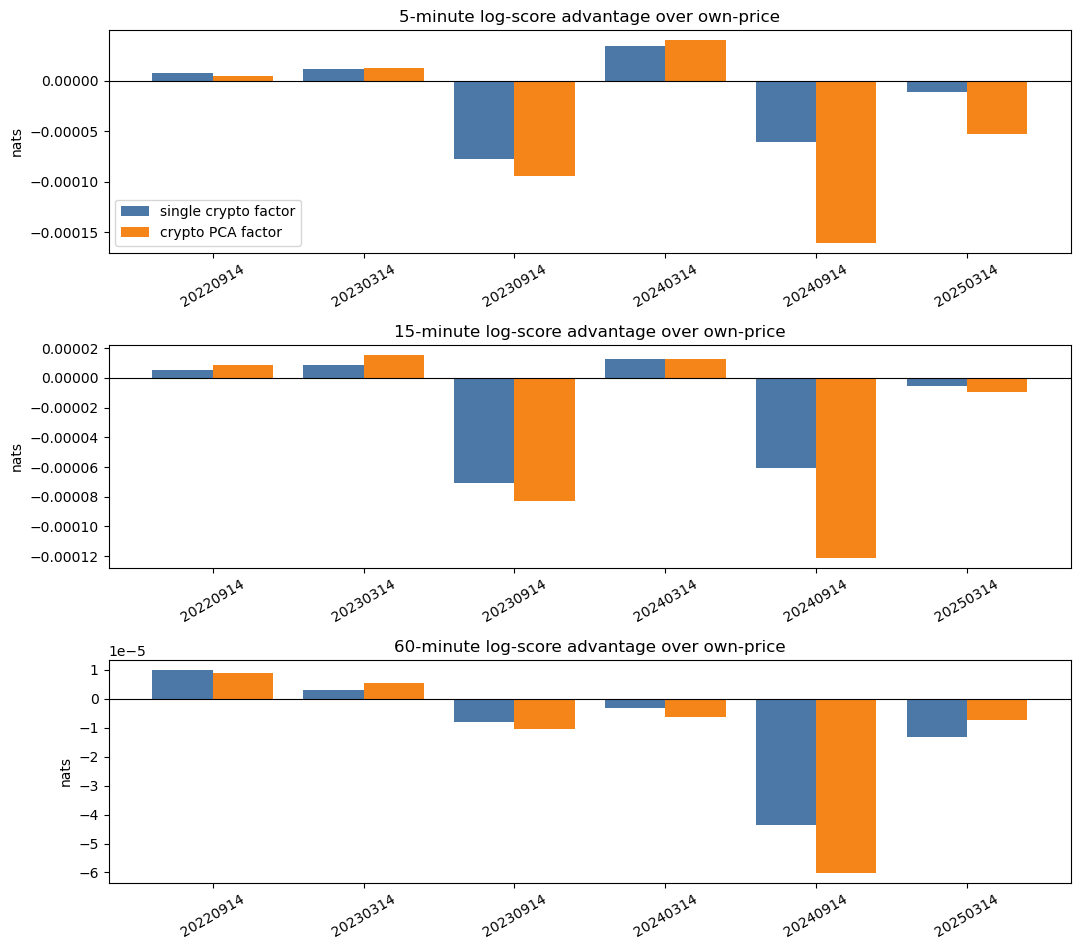

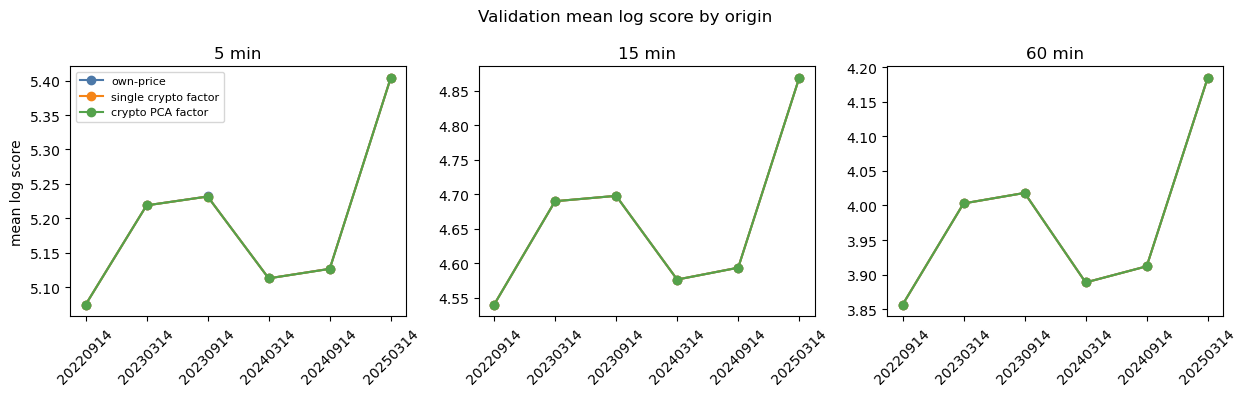

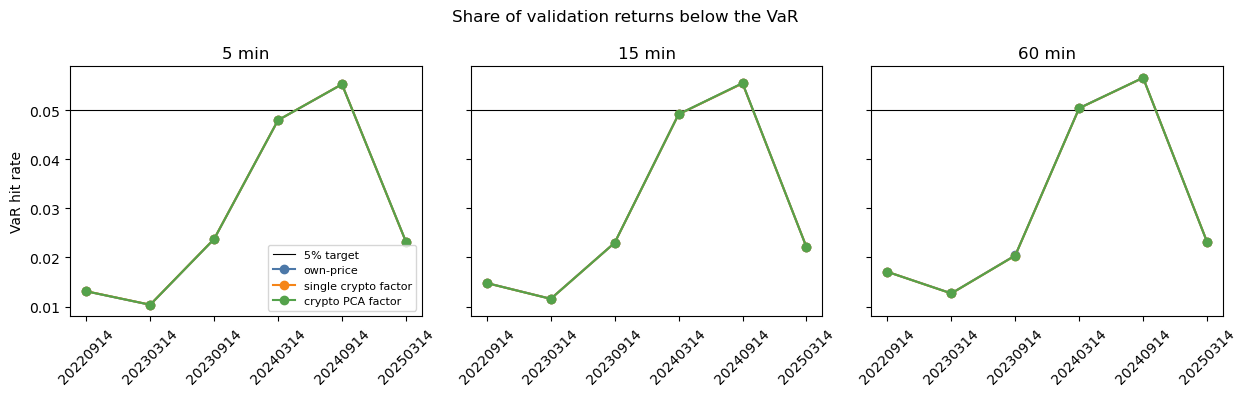

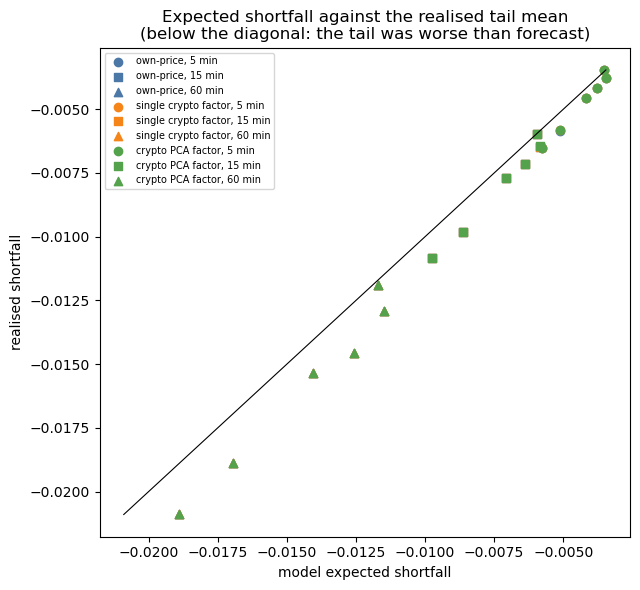

In [5]:
plot_advantage_by_origin(evaluation.scores, benchmark=BENCHMARK, candidates=CANDIDATES, labels=LABELS)
plt.show()
plot_score_levels(evaluation.scores, models=MODELS, labels=LABELS)
plt.show()
plot_var_hit_rates(evaluation.scores, models=MODELS, alpha=ALPHA, labels=LABELS)
plt.show()
plot_shortfall(evaluation.scores, models=MODELS, labels=LABELS)
plt.show()

## Calibration diagnostics

The probability integral transform (PIT) of a well-calibrated density is uniform. Each panel plots PIT quantiles against uniform quantiles. The diagonal is perfect calibration. Faint lines are individual origins and heavy lines are their mean. An S-shaped curve means the tails carry the wrong amount of probability. A candidate improves calibration only if its heavy line sits closer to the diagonal than the benchmark's.

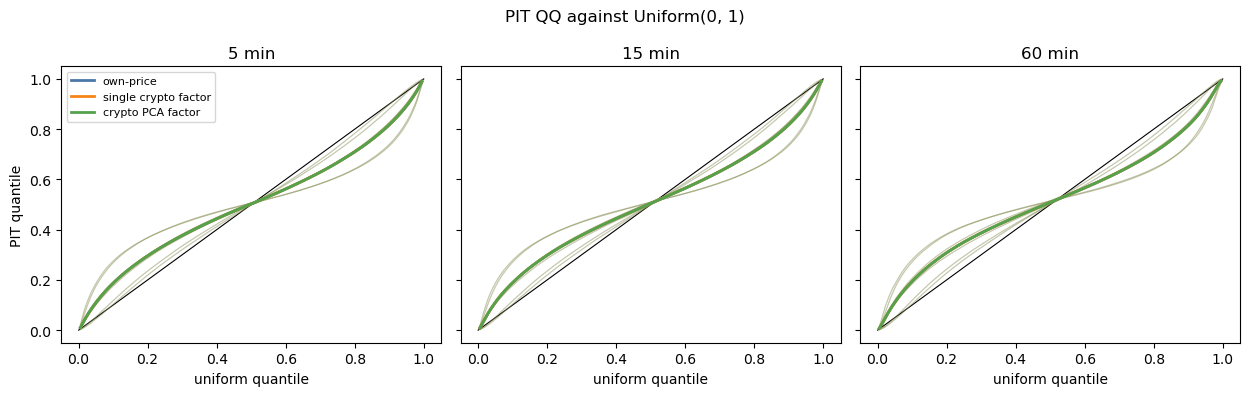

In [6]:
plot_pit_qq(evaluation.pit_qq, models=MODELS, labels=LABELS)
plt.show()

## Fitted densities and state

Every model is a linear forecast of the mean plus an H1-family residual density. Each model is refitted once on all development labels, for display only; the scores above come from the rolling origins.

1. The residual table shows each model's residual family, degrees of freedom, and scale.
2. The coefficient table and bar charts show how far one standard deviation of each lagged feature moves the forecast mean, in basis points. Values near zero mean the feature carries almost no forecast information.
3. The density panels show the benchmark's residual histogram with every model's fitted residual density. Curves that overlap mean the candidates barely change the forecast distribution.

Panel return construction excluded 1 non-consecutive/initial rows
Dropped 61 own_price training labels with unavailable lagged features
Dropped 61 single_factor training labels with unavailable lagged features
Dropped 61 pca_factor training labels with unavailable lagged features
Dropped 61 own_price display labels with unavailable lagged features
Dropped 61 single_factor display labels with unavailable lagged features
Dropped 61 pca_factor display labels with unavailable lagged features
Dropped 61 own_price training labels with unavailable lagged features
Dropped 61 single_factor training labels with unavailable lagged features
Dropped 61 pca_factor training labels with unavailable lagged features
Dropped 61 own_price display labels with unavailable lagged features
Dropped 61 single_factor display labels with unavailable lagged features
Dropped 61 pca_factor display labels with unavailable lagged features
Dropped 61 own_price training labels with unavailable lagged features
Dropped 61

Residual density of each model, fitted on all development labels


observations   intercept     family      df      scale
horizon_minutes model                                                                
5               own_price           2677914 4.34221e-06  student_t 4.07811 0.00141241
                single_factor       2677914 4.34221e-06  student_t 4.07809  0.0014124
                pca_factor          2677914 4.34221e-06  student_t 4.07809 0.00141239
15              own_price           2677904 1.30262e-05  student_t 4.13694 0.00239931
                single_factor       2677904 1.30262e-05  student_t 4.13694 0.00239929
                pca_factor          2677904 1.30262e-05  student_t 4.13696 0.00239929
60              own_price           2677859  5.2145e-05  student_t 4.21666 0.00471942
                single_factor       2677859  5.2145e-05  student_t 4.21664  0.0047194
                pca_factor          2677859  5.2145e-05  student_t 4.21664  0.0047194

Forecast mean shift per one-standard-deviation feature move, in basis points


horizon_minutes                               5         15        60
model         feature                                               
own_price     own_realised_volatility   0.190398  0.539308   1.53798
              own_return               -0.383662 -0.444688 -0.725666
pca_factor    own_realised_volatility   0.189608  0.538017   1.53643
              own_return               -0.335006 -0.365101 -0.630089
              pca_residual             -0.101452 -0.165949 -0.199288
single_factor own_realised_volatility   0.189808  0.538315   1.53678
              own_return               -0.331146 -0.356247 -0.618711
              single_factor_residual  -0.0859897 -0.144813 -0.175129

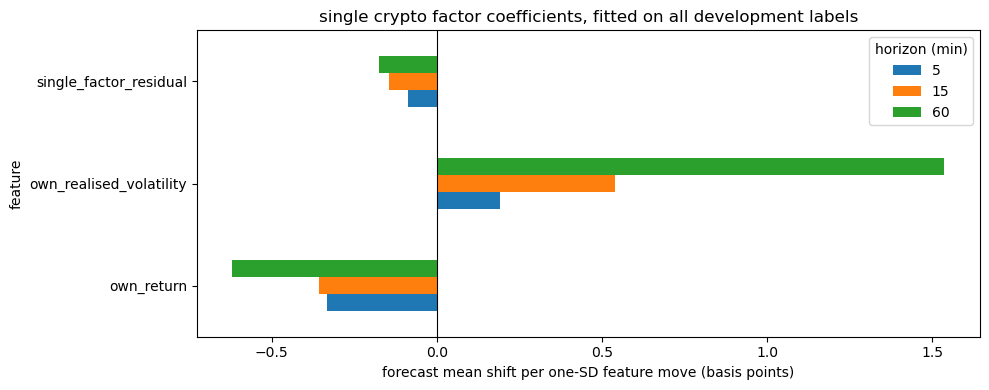

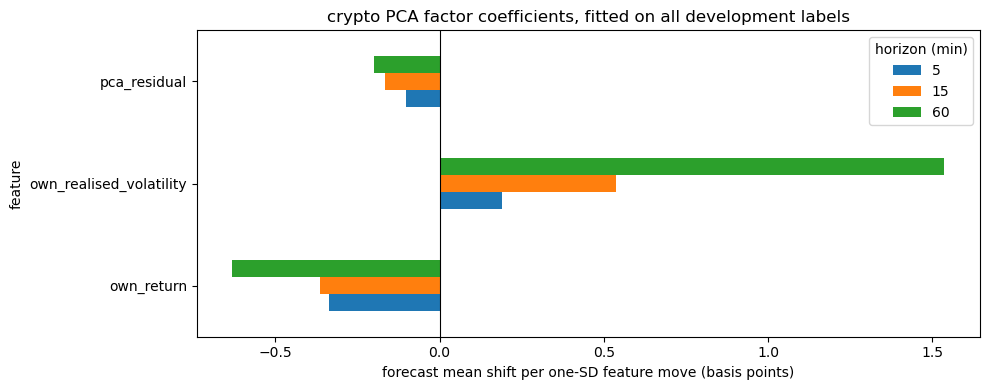

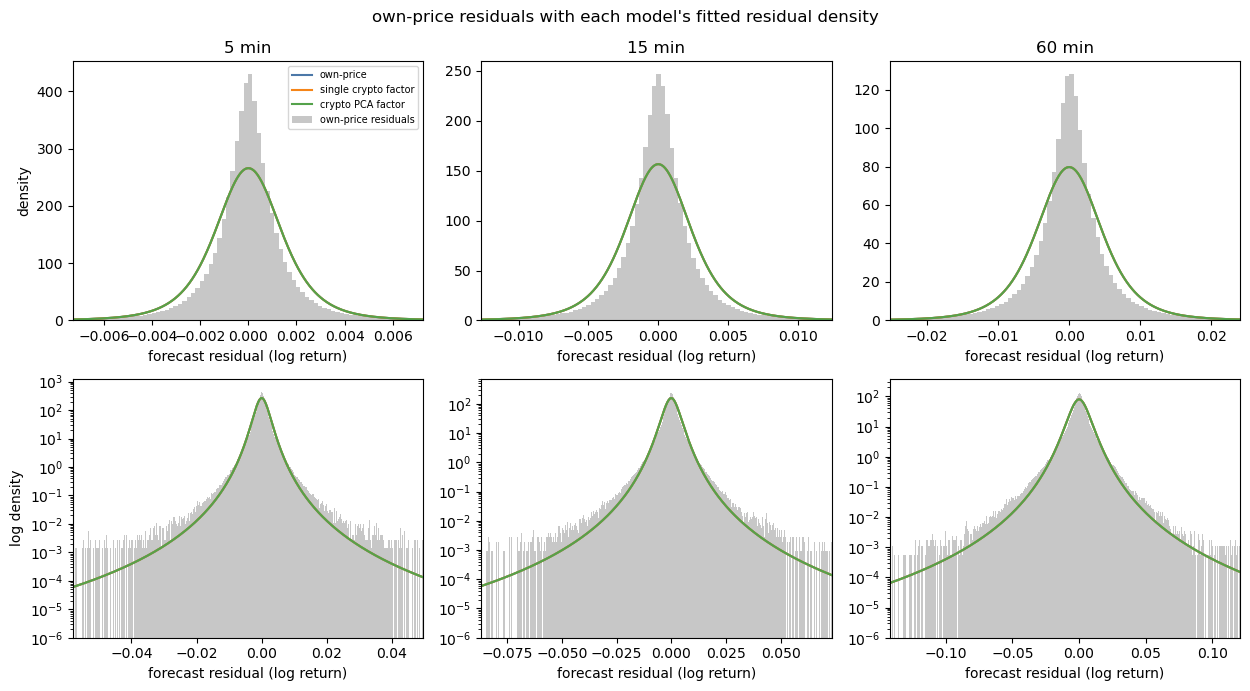

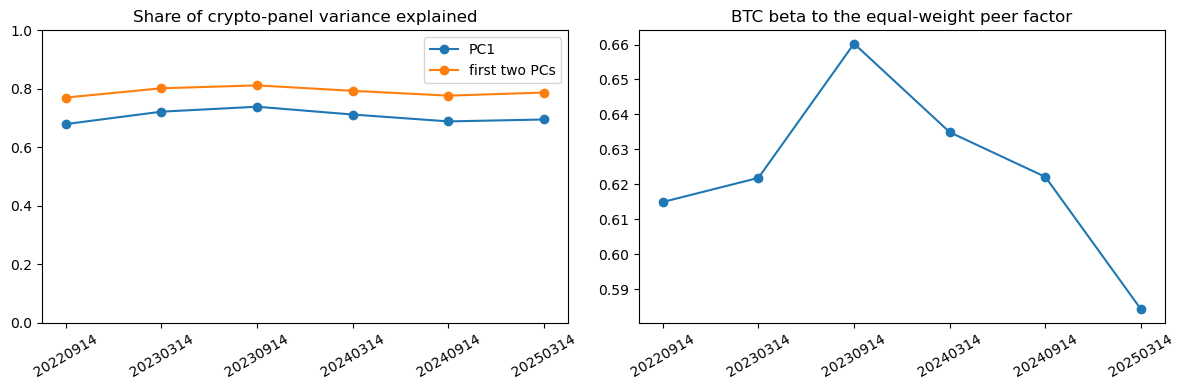

In [7]:
from research.report import conditional_coefficients, plot_coefficients, residual_parameters

fits = h3_development_fits(panel_closes, h1_record, CONFIG)
parameters = residual_parameters(fits)
coefficients = conditional_coefficients(fits)
print("Residual density of each model, fitted on all development labels")
display(parameters.set_index(["horizon_minutes", "model"]))
print("Forecast mean shift per one-standard-deviation feature move, in basis points")
display(
    coefficients.pivot_table(
        index=["model", "feature"], columns="horizon_minutes", values="shift_per_sd_bps", aggfunc="first"
    )
)
for model in CANDIDATES:
    plot_coefficients(coefficients, model=model, labels=LABELS)
    plt.show()

colors = model_colors(MODELS)
samples, curves = {}, {}
for horizon in sorted({fit.horizon_minutes for fit in fits}):
    by_model = {fit.model: fit for fit in fits if fit.horizon_minutes == horizon}
    samples[horizon] = by_model[BENCHMARK].residuals
    curves[horizon] = [
        (LABELS[model], by_model[model].density.residual.log_density, {"color": colors[model]})
        for model in MODELS
    ]
plot_density_panels(
    samples,
    curves,
    title=f"{LABELS[BENCHMARK]} residuals with each model's fitted residual density",
    sample_label=f"{LABELS[BENCHMARK]} residuals",
    xlabel="forecast residual (log return)",
)
plt.show()

diagnostics = evaluation.diagnostics.copy()
diagnostics["pc1"] = diagnostics["explained_variance_ratio"].map(lambda values: values[0])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(diagnostics["origin"], diagnostics["pc1"], marker="o", label="PC1")
axes[0].plot(diagnostics["origin"], diagnostics["absorption_ratio"], marker="o", label="first two PCs")
axes[0].set_ylim(0, 1)
axes[0].set_title("Share of crypto-panel variance explained")
axes[0].legend()
axes[1].plot(diagnostics["origin"], diagnostics["single_factor_beta"], marker="o")
axes[1].set_title("BTC beta to the equal-weight peer factor")
for axis in axes:
    axis.tick_params(axis="x", labelrotation=30)
fig.tight_layout()
plt.show()
residual_shift = coefficients.loc[coefficients["feature"].isin(["single_factor_residual", "pca_residual"]), "shift_per_sd_bps"].abs().max()
NOTES = [
    f"Crypto structure: PC1 explains {diagnostics['pc1'].min():.0%} to {diagnostics['pc1'].max():.0%} of crypto-panel "
    f"variance and BTC's beta to its peers is {diagnostics['single_factor_beta'].min():.2f} to "
    f"{diagnostics['single_factor_beta'].max():.2f}. The markets move together, but the lagged residual moves the "
    f"BTC forecast mean by at most {residual_shift:.3f} basis points per standard deviation, which is why it adds no forecast value."
]

## 18. Result

The next cell states the development result in plain English: the answer, why, how large the effect is at each horizon, whether the densities are calibrated, and what to do with the result.

In [8]:
result_lines = plain_english_result(
    question=QUESTION,
    verdict=verdict,
    reading=reading,
    calibration=calibration,
    failures=len(evaluation.failures),
    labels=LABELS,
)
for line in [*result_lines[:-1], *NOTES, result_lines[-1]]:
    print(line)
    print()

Question: Do lagged factor residuals from other crypto majors improve the BTCUSDT return density beyond BTC's own price history?

Answer: no. The null is accepted and the working forecast is own-price.

Why: No factor state beats own-price history at every horizon.

Against own-price, single crypto factor changed the geometric-mean forecast density by -0.0016% at 5 minutes (ahead at 3 of 6 origins); -0.0018% at 15 minutes (ahead at 3 of 6 origins); -0.0009% at 60 minutes (ahead at 2 of 6 origins).

Against own-price, crypto PCA factor changed the geometric-mean forecast density by -0.0042% at 5 minutes (ahead at 3 of 6 origins); -0.0030% at 15 minutes (ahead at 3 of 6 origins); -0.0012% at 60 minutes (ahead at 2 of 6 origins).

Tail calibration: no model is calibrated. The 5% VaR is breached 2.18% to 2.35% of the time, and the Bonferroni test rejects coverage for every model and horizon. Every model breaches its VaR less often than it should, so each overstates tail risk. None of these

## 19. Decision

The next cell records the development result on `EXP-H03`. Accepting or rejecting the development null sets status `Exploratory`, names the working forecast in `result`, and leaves the lifecycle decision blank. Incomplete evidence sets `Deferred`. Only `confirm_h3`, run on the sealed year, writes `retain` or `reject`. The cell then lists what still blocks that confirmation.

In [9]:
record = record_development_decision(
    RECORD_PATH,
    verdict,
    experiment_id=EXPERIMENT_ID,
    dataset_id=DATASET_ID,
    dataset_digest=DATASET_DIGEST,
    config=CONFIG,
    root=root,
)
print(f"Recorded on {record.experiment_id}: status={record.status}, result={record.result}, "
      f"lifecycle decision={record.decision or '(blank)'}")
display(pd.Series(asdict(record), name="registry value").to_frame())
blockers = confirmation_blockers(
    root=root,
    record=record,
    h1_record=GATE_H1_RECORD,
    dataset_objects=GATE_OBJECTS,
)
if blockers:
    print("Sealed confirmation is blocked:")
    for blocker in blockers:
        print(f"- {blocker}")
else:
    print("Sealed confirmation has no outstanding blockers. It can be run once, below.")

Research code version is dirty: 53df8883077c46048647a4e3a1a88f5d333bded6+dirty


Recorded on EXP-H03: status=Exploratory, result=own_price, lifecycle decision=(blank)


,registry value
experiment_id,EXP-H03
hypothesis,Lagged single-factor and PCA residual state im...
null,Lagged factor residual state adds no density-f...
parent_hypothesis,EXP-H01
dataset_id,binance-majors-1m
dataset_digest,521d37ac1ceb1825b8734b8128760b88acfc6d41010c0d...
code_version,53df8883077c46048647a4e3a1a88f5d333bded6+dirty
config_digest,67ee486a1fab1d469d479954a661fb5acbe82ae1da53ee...
status,Exploratory
result,own_price


Research code version is dirty: 53df8883077c46048647a4e3a1a88f5d333bded6+dirty


Sealed confirmation is blocked:
- the research code is uncommitted (53df8883077c46048647a4e3a1a88f5d333bded6+dirty)
- H1 has not been confirmed on its sealed year
- 6 stored object(s) have no immutable version id, for example ohlcv/binance/BTCUSDT/1m/2026.parquet


## Sealed confirmation

This cell reads the final 12 months once, writes `retain` or `reject` with a run id, and cannot be repeated. It is off by default. Set `RUN_SEALED_CONFIRMATION = True` only after the blockers printed above are cleared and the code is committed.

In [10]:
RUN_SEALED_CONFIRMATION = False

if not RUN_SEALED_CONFIRMATION:
    print("Sealed confirmation was not run. No sealed labels were read.")
else:
    if blockers:
        raise RuntimeError("sealed confirmation is blocked: " + "; ".join(blockers))

    from research.evaluate import confirm_h3

    confirmation = confirm_h3(
        panel_closes,
        record,
        h1_record,
        panel_manifest=panel_manifest,
        root=root,
        record_path=RECORD_PATH,
    )
    print(f"decision={confirmation.record.decision} result={confirmation.record.result} "
          f"status={confirmation.record.status} run_id={confirmation.record.run_id}")
    display(confirmation.scores)

Sealed confirmation was not run. No sealed labels were read.


## 20. Reusable implementation extracted

Panel alignment, factor-state estimation, conditional density scoring, and lifecycle gates live in `research.factors`, `research.manifest`, and `research.evaluate`. `research.report` holds the shared reading, plots, and registration. A rejected H3 result must not enable crypto factor features in Wave or Tide.

## 21. Next experiment

H20 (`05_cross_market_factors`) tests lagged markets outside crypto and keeps this single-factor residual as an ablation. A revised universe, lag, or factor count requires a new experiment id.